# ARTI403 – Image Processing
## Lab 6: Frequency Domain

**Name:** Mohammed Moayed Alquriniy

**Student ID:** 2240007325

**Session Outcome:** Write a program that implements fundamental image processing algorithms.

---
This notebook contains:
1. **Procedural Task #1** – Filtering in the frequency domain using the Laplacian filter.
2. **Assessment Task #1** – Applying the Sobel filters (X and Y) in the frequency domain on the Cameraman image.

## 0. Imports & Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io
from skimage.transform import resize
from numpy.fft import fft2, ifft2, fftshift, ifftshift

# Folder where the images used / produced in this lab are saved
IMG_DIR = "images"
os.makedirs(IMG_DIR, exist_ok=True)

# Load cameraman image (already grayscale) and save a copy of the original image used
camera = data.camera()
io.imsave(os.path.join(IMG_DIR, "cameraman.png"), camera)
print("Original image shape:", camera.shape, "| dtype:", camera.dtype)

Original image shape: (512, 512) | dtype: uint8


## 1. Procedural Task #1: Filtering in the Frequency Domain (Laplacian)

The Laplacian in the frequency domain is defined as:

**H(u, v) = −4π² (u² + v²)**

The filtered image is obtained by multiplying the image spectrum by H(u, v) and taking the inverse FFT:

**g(x, y) = IFFT{ F(u, v) · H(u, v) }**

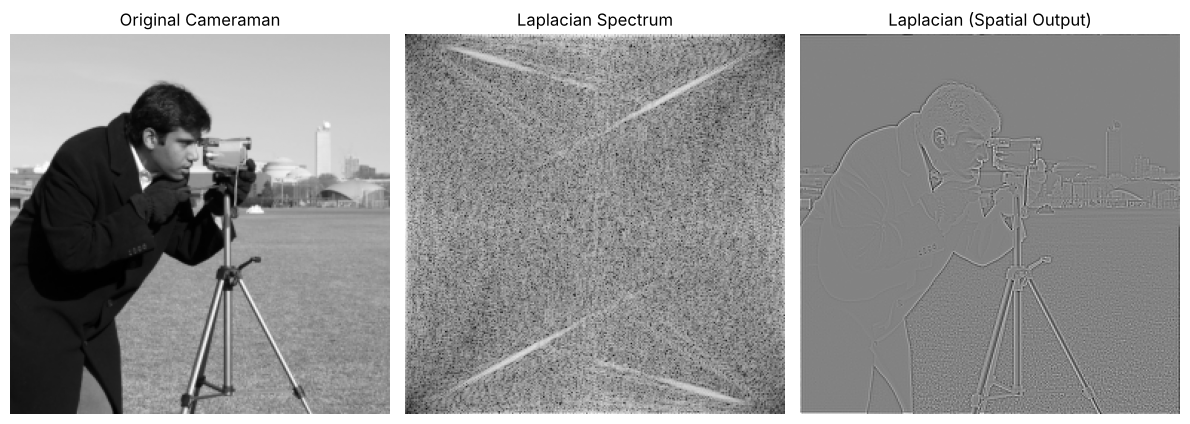

In [2]:
# Resize for faster FFT
image = resize(camera, (256, 256))

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "task1_laplacian_frequency.png"), dpi=150, bbox_inches='tight')
plt.show()

**Observation:** The Laplacian is a high-pass filter. Its frequency response is zero at the centre (DC) and grows with
distance from the origin, so low frequencies (smooth regions) are suppressed and high frequencies (edges and fine details)
are kept. The spatial output therefore highlights the edges of the cameraman, the camera and the tripod.

## 2. Assessment Task #1: Sobel Filters in the Frequency Domain

**Steps:**
1. Load and resize the Cameraman image.
2. Define the Sobel X and Sobel Y kernels.
3. Zero-pad each kernel to the image size, centre it, then apply `ifftshift` so the kernel centre moves to (0, 0) before the FFT (this prevents a spatial shift in the output).
4. Compute the FFT of the image and the FFT of each padded kernel.
5. Multiply in the frequency domain (convolution theorem: f ∗ h ⇔ F · H).
6. Take the inverse FFT, then compute the gradient magnitude G = √(Gx² + Gy²).
7. Plot the results.

### 2.1 Load and resize image

In [3]:
# Load and resize image
image = resize(data.camera(), (256, 256))
M, N = image.shape
print("Resized image shape:", image.shape)

Resized image shape: (256, 256)


### 2.2 Sobel kernels and centred embedding

In [4]:
# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

### 2.3 FFT of the image and of the Sobel filters

In [5]:
# Compute FFT of image
F_img = fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

print("F_img shape:", F_img.shape, "| H_x shape:", H_x.shape, "| H_y shape:", H_y.shape)

F_img shape: (256, 256) | H_x shape: (256, 256) | H_y shape: (256, 256)


### 2.4 Visualise the frequency responses of the Sobel filters

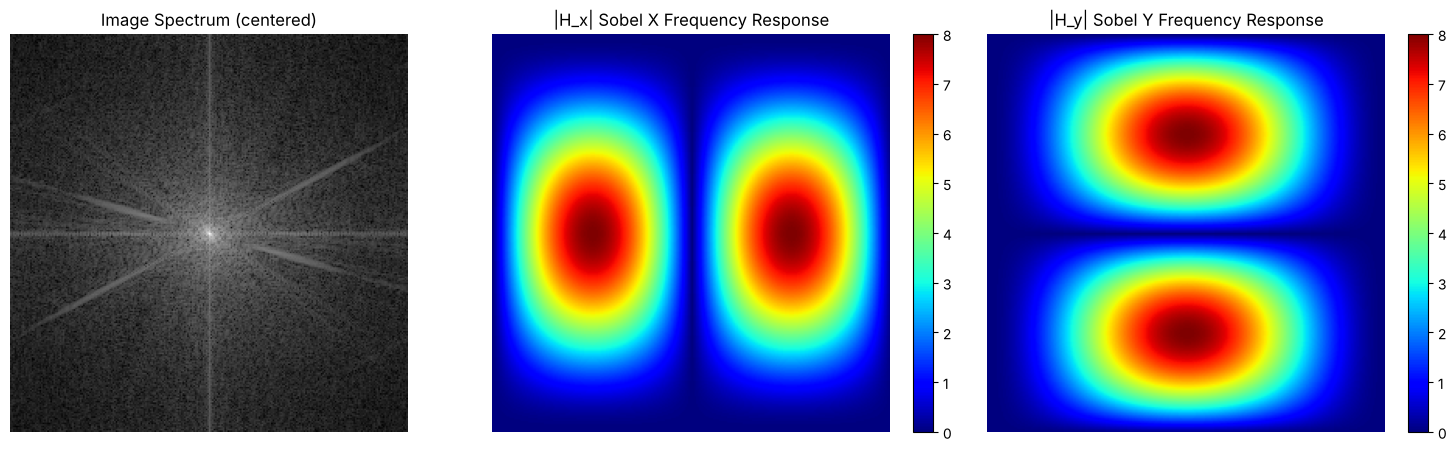

In [6]:
plt.figure(figsize=(15, 4.5))

plt.subplot(1, 3, 1)
plt.imshow(np.log(1 + np.abs(fftshift(F_img))), cmap='gray')
plt.title('Image Spectrum (centered)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.abs(fftshift(H_x)), cmap='jet')
plt.title('|H_x| Sobel X Frequency Response')
plt.colorbar(fraction=0.046)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(np.abs(fftshift(H_y)), cmap='jet')
plt.title('|H_y| Sobel Y Frequency Response')
plt.colorbar(fraction=0.046)
plt.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "task2_sobel_frequency_responses.png"), dpi=150, bbox_inches='tight')
plt.show()

**Observation:** The magnitude of H_x is zero along the vertical line v = 0 and largest at mid horizontal
frequencies, so Sobel X responds to intensity changes along the horizontal direction (vertical edges).
H_y is the same pattern rotated by 90°, so Sobel Y responds to horizontal edges. Both are zero at the
centre (DC), which means they are high-pass / band-pass filters that remove the average brightness.

### 2.5 Multiply in the frequency domain and inverse FFT

In [7]:
# Multiply in the frequency domain
F_sobel_x = F_img * H_x
F_sobel_y = F_img * H_y

# Back to the spatial domain (imaginary part is only numerical noise)
sobel_x_img = np.real(ifft2(F_sobel_x))
sobel_y_img = np.real(ifft2(F_sobel_y))

# Gradient magnitude
sobel_mag = np.sqrt(sobel_x_img**2 + sobel_y_img**2)

print("Max imaginary part (should be ~0):", np.abs(np.imag(ifft2(F_sobel_x))).max())
print("Sobel X range:", sobel_x_img.min().round(3), "to", sobel_x_img.max().round(3))
print("Sobel Y range:", sobel_y_img.min().round(3), "to", sobel_y_img.max().round(3))
print("Magnitude range:", sobel_mag.min().round(3), "to", sobel_mag.max().round(3))

Max imaginary part (should be ~0): 7.658579795395912e-16
Sobel X range: -3.18 to 3.303
Sobel Y range: -2.979 to 2.665
Magnitude range: 0.0 to 3.448


### 2.6 Plot the results

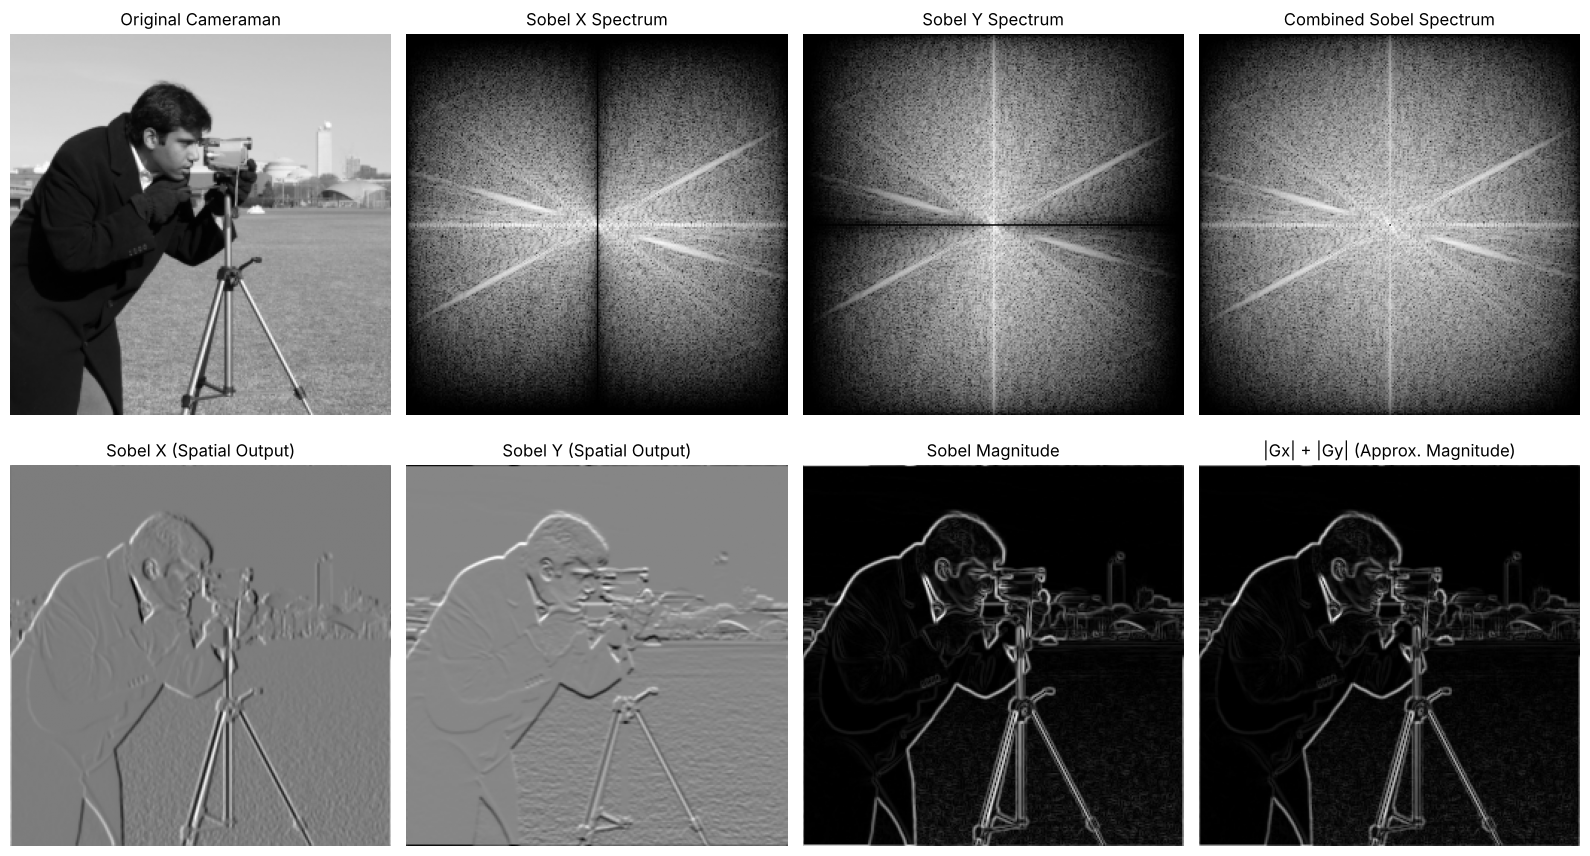

In [8]:
# Plot
plt.figure(figsize=(16, 9))

plt.subplot(2, 4, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(2, 4, 2)
plt.imshow(np.log(1 + np.abs(fftshift(F_sobel_x))), cmap='gray')
plt.title('Sobel X Spectrum')
plt.axis('off')

plt.subplot(2, 4, 3)
plt.imshow(np.log(1 + np.abs(fftshift(F_sobel_y))), cmap='gray')
plt.title('Sobel Y Spectrum')
plt.axis('off')

plt.subplot(2, 4, 4)
plt.imshow(np.log(1 + np.abs(fftshift(F_sobel_x)) + np.abs(fftshift(F_sobel_y))), cmap='gray')
plt.title('Combined Sobel Spectrum')
plt.axis('off')

plt.subplot(2, 4, 5)
plt.imshow(sobel_x_img, cmap='gray')
plt.title('Sobel X (Spatial Output)')
plt.axis('off')

plt.subplot(2, 4, 6)
plt.imshow(sobel_y_img, cmap='gray')
plt.title('Sobel Y (Spatial Output)')
plt.axis('off')

plt.subplot(2, 4, 7)
plt.imshow(sobel_mag, cmap='gray')
plt.title('Sobel Magnitude')
plt.axis('off')

plt.subplot(2, 4, 8)
plt.imshow(np.abs(sobel_x_img) + np.abs(sobel_y_img), cmap='gray')
plt.title('|Gx| + |Gy| (Approx. Magnitude)')
plt.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "task2_sobel_frequency_results.png"), dpi=150, bbox_inches='tight')
plt.show()

### 2.7 Verification: frequency domain vs. spatial domain

By the convolution theorem, multiplying in the frequency domain should give exactly the same result as
**circular convolution** in the spatial domain. We verify this with `scipy.ndimage.convolve` using `mode='wrap'`
(wrap = circular boundary, which matches the periodic assumption of the DFT).

Max |difference| Sobel X  : 1.4883927423881005e-15
Max |difference| Sobel Y  : 2.8380076066980564e-15
Max |difference| Magnitude: 2.680147770384167e-15
Results match: True


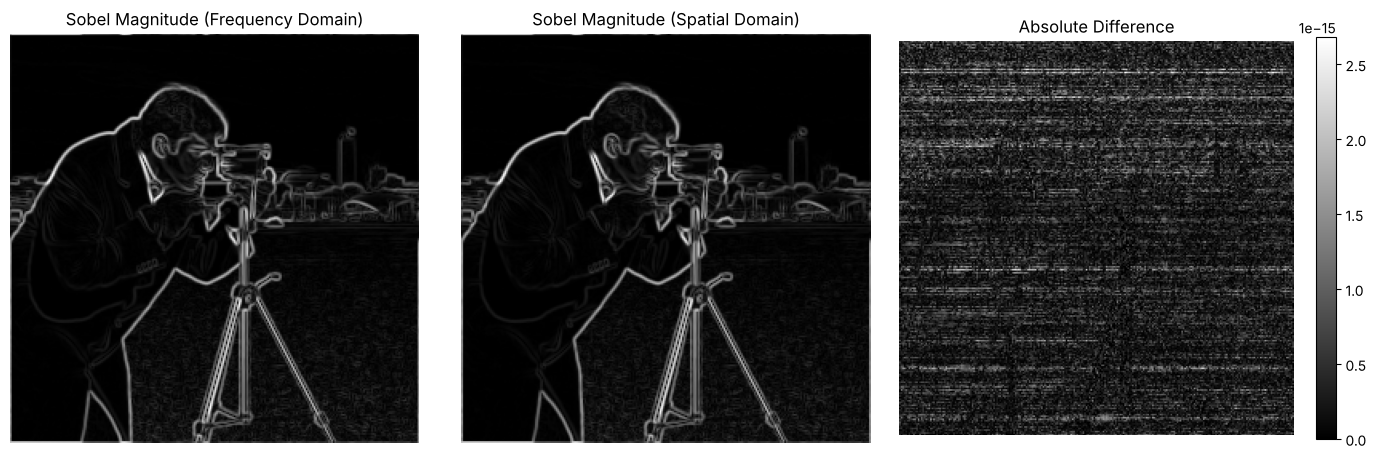

In [9]:
from scipy.ndimage import convolve

spatial_x = convolve(image, sobel_x, mode='wrap')
spatial_y = convolve(image, sobel_y, mode='wrap')
spatial_mag = np.sqrt(spatial_x**2 + spatial_y**2)

print("Max |difference| Sobel X  :", np.abs(spatial_x - sobel_x_img).max())
print("Max |difference| Sobel Y  :", np.abs(spatial_y - sobel_y_img).max())
print("Max |difference| Magnitude:", np.abs(spatial_mag - sobel_mag).max())
print("Results match:", np.allclose(spatial_mag, sobel_mag))

plt.figure(figsize=(14, 4.5))
plt.subplot(1, 3, 1)
plt.imshow(sobel_mag, cmap='gray')
plt.title('Sobel Magnitude (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(spatial_mag, cmap='gray')
plt.title('Sobel Magnitude (Spatial Domain)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(np.abs(spatial_mag - sobel_mag), cmap='gray')
plt.title('Absolute Difference')
plt.colorbar(fraction=0.046)
plt.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "task2_frequency_vs_spatial.png"), dpi=150, bbox_inches='tight')
plt.show()

**Observation:** The difference between the two results is at the level of floating-point error (~1e-15),
which confirms that filtering by multiplication in the frequency domain is equivalent to convolution in the spatial domain.

## 3. Discussion

- **Sobel X** highlights **vertical edges** (e.g., the tripod legs and the vertical sides of the camera and the person),
  while **Sobel Y** highlights **horizontal edges** (e.g., the shoulders and the horizon line).
- The **gradient magnitude** combines both directions and gives a complete edge map of the image.
- Centering the kernel and applying `ifftshift` before the FFT is essential; without it, the kernel centre would be at
  (1, 1) instead of (0, 0), and the output image would be shifted by one pixel.
- Compared to the **Laplacian** (Task #1), which is a second derivative and isotropic (same response in all directions),
  Sobel is a first-derivative operator that is **directional** and includes smoothing perpendicular to the derivative
  direction, which makes it less sensitive to noise.

## 4. What I Learned

- How to move an image to the frequency domain with the 2D FFT and back with the inverse FFT.
- How a filter can be defined directly in the frequency domain (Laplacian) or obtained from a spatial kernel by zero-padding it to the image size (Sobel).
- Why `ifftshift` is needed to place the kernel centre at the origin before taking its FFT.
- That the convolution theorem lets us replace spatial convolution with an element-wise multiplication of spectra, and I verified that both give the same result.
- How to read a filter's frequency response: both Laplacian and Sobel suppress the DC component, so they act as edge detectors (high-pass), and Sobel's response is directional.